In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import yfinance as yf

La función get_current_futures_curve hace lo siguiente: toma una "foto" hoy de cuánto cuesta el gas natural para cada mes futuro (del mes 1 hasta el mes 60) y le quita el efecto del clima (invierno/verano) para ver la tendencia real.

`today = datetime.date.today()`: Obtiene la fecha actual de tu computadora (por ejemplo, 2026-11-12).

`tickers = []`: Crea una lista vacía donde iremos guardando los nombres de los contratos que le pediremos a Yahoo Finance (ej. ['NGZ26.NYM', 'NGF27.NYM', ...]).

`maturities = []`: Crea otra lista vacía para guardar el número de meses que faltan para cada vencimiento ([1, 2, 3, ..., 60]), que luego será el eje X de la gráfica.

In [4]:
def get_current_futures_curve(months_ahead=60):
    # Commodity futures month codes (January=F ... December=Z)
    month_codes = {
        1: 'F',
        2: 'G',
        3: 'H',
        4: 'J',
        5: 'K',
        6: 'M',
        7: 'N',
        8: 'Q',
        9: 'U',
        10: 'V',
        11: 'X',
        12: 'Z',
    }

    today = datetime.date.today()
    tickers = []
    maturities = []

    for m in range(1, months_ahead + 1):
        # Calculate expiration month and year
        exp_month = (today.month + m - 1) % 12 + 1
        exp_year = today.year + (today.month + m - 1) // 12
        short_year = str(exp_year)[-2:]
        # Example: if we are in November (11) and m = 3, (11 + 3 - 1) % 12 + 1 = 1 % 12 + 1 = 2 (February).
        # Example: if we are in November (11), 2026 and m = 3, 2026 + (11 + 3 - 1) // 12 = 2026 + 1 = 2027

        ticker = f'NG{month_codes[exp_month]}{short_year}.NYM'
        tickers.append(ticker)
        maturities.append(m)

    # Download latest available closing prices
    data = yf.download(tickers, period='5d', progress=False)['Close']
    # forward fill: in case some tickers have missing data for the last few days, we take the last available price
    latest_prices = data.ffill().iloc[-1] 
    

    df_curve = pd.DataFrame(
        {'Maturity_Months': maturities, 'Ticker': tickers}
    ).set_index('Ticker')

    df_curve['Original_Price'] = latest_prices
    df_curve = df_curve.dropna()

    # Deseasonalization (annual cycle = 12 months)
    # Note: The paper uses X-12-ARIMA; here we use standard seasonal decomposition
    decomposition = seasonal_decompose(
        df_curve['Original_Price'],
        model='additive',
        period=12,
        extrapolate_trend='freq',
    )
    df_curve['Deseasonalized_Price'] = (
        df_curve['Original_Price'] - decomposition.seasonal
    )

    return df_curve

`decomposition = seasonal_decompose(df_curve['Original_Price'], model='additive', period=12)`: Separa la curva de precios en tres partes: tendencia, estacionalidad y residuo. Al poner period=12, le indicamos que el ciclo estacional del gas natural se repite cada 12 meses (más caro en invierno por calefacción, más barato en primavera/otoño).

`seasonal_component = decomposition.seasonal.bfill().ffill()`: Extrae únicamente el componente estacional (cuánto sube o baja el precio por culpa de la época del año) y rellena los extremos con `.bfill()` (backward fill) y `.ffill()` (forward fill) para asegurar que no haya valores nulos.

`df_curve['Deseasonalized_Price'] = df_curve['Original_Price'] - seasonal_component`: Resta el efecto estacional al precio original. El resultado es la línea roja de la Figura 1 (Underlying Futures Prices), que muestra el precio "limpio" del gas sin los picos artificiales de cada invierno.   

`return df_curve`: Devuelve la tabla final lista con las columnas Maturity_Months, Original_Price y Deseasonalized_Price para poder graficarla.

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: NGF32.NYM"}}}
$NGF32.NYM: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: NGU32.NYM"}}}
$NGU32.NYM: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$NGN32.NYM: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$NGQ32.NYM: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$NGZ31.NYM: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")

5 Failed downloads:
['NGF32.NYM', 'NGU32.NYM', 'NGN32.NYM', 'NGQ32.NYM', 'NGZ31.NYM']: possibly delisted; no price data found  (period=

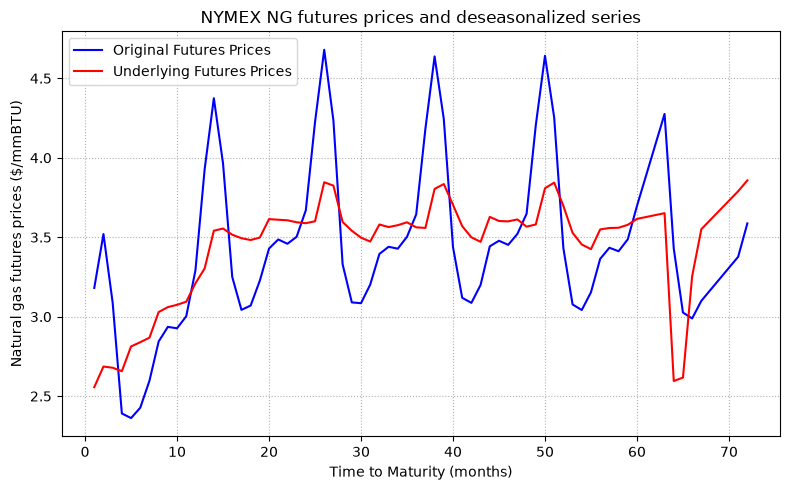

In [5]:
# Execute and plot (Replication of Figure 1)
df_fig1 = get_current_futures_curve(months_ahead=72)

plt.figure(figsize=(8, 5))
plt.plot(
    df_fig1['Maturity_Months'],
    df_fig1['Original_Price'],
    color='blue',
    label='Original Futures Prices',
)
plt.plot(
    df_fig1['Maturity_Months'],
    df_fig1['Deseasonalized_Price'],
    color='red',
    label='Underlying Futures Prices',
)

plt.title('NYMEX NG futures prices and deseasonalized series')
plt.xlabel('Time to Maturity (months)')
plt.ylabel('Natural gas futures prices ($/mmBTU)')
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

En mercados reales, los contratos a tan largo plazo tienen muy poca liquidez o todavía no tienen operaciones registradas en los últimos 5 días en Yahoo Finance (lo cual coincide exactamente con lo que advierten los autores en la página 14 del artículo: "we must stress the lower liquidity of futures contracts as the time to maturity increases")

In [13]:
def get_eia_historical_2004_2005():
    # Official EIA direct URLs for daily NYMEX natural gas futures
    # RNGC1d = 1-month maturity, RNGC4d = 4-month maturity (max free maturity on EIA)
    df_f01 = pd.read_excel(
        'https://www.eia.gov/dnav/ng/hist_xls/RNGC1d.xls',
        sheet_name='Data 1',
        skiprows=2,
    )
    df_f04 = pd.read_excel(
        'https://www.eia.gov/dnav/ng/hist_xls/RNGC4d.xls',
        sheet_name='Data 1',
        skiprows=2,
    )

    df_f01.columns = ['Date', 'F01']
    df_f04.columns = ['Date', 'F04']

    df = pd.merge(df_f01, df_f04, on='Date').dropna()
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values('Date').set_index('Date')

    # Deseasonalize over the entire historical series (~252 trading days/year)
    # to capture the annual seasonal pattern before slicing the study window
    decomp_f01 = seasonal_decompose(
        df['F01'], model='additive', period=252, extrapolate_trend='freq'
    )
    decomp_f04 = seasonal_decompose(
        df['F04'], model='additive', period=252, extrapolate_trend='freq'
    )

    df['F01_deseas'] = df['F01'] - decomp_f01.seasonal
    df['F04_deseas'] = df['F04'] - decomp_f04.seasonal

    # Filter exact dates from the paper (January 5, 2004 to April 29, 2005)
    df_paper = df.loc['2004-01-05':'2005-04-29'].copy()
    df_paper['Trading_Days'] = range(1, len(df_paper) + 1)

    return df_paper

C:\Users\Equipo\AppData\Local\Temp\ipykernel_12468\3052554519.py:24: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp_f01 = seasonal_decompose(
C:\Users\Equipo\AppData\Local\Temp\ipykernel_12468\3052554519.py:27: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp_f04 = seasonal_decompose(


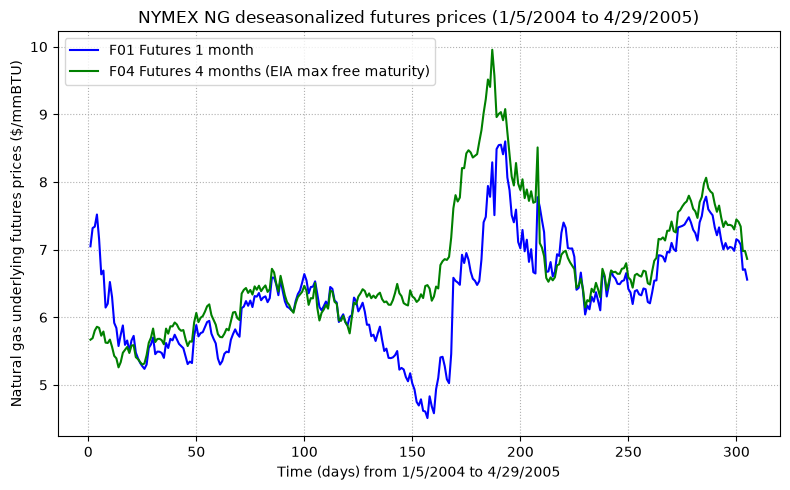

In [17]:
# Execute and plot (Replication of Figure 2)
df_fig2 = get_eia_historical_2004_2005()

plt.figure(figsize=(8, 5))
plt.plot(
    df_fig2['Trading_Days'],
    df_fig2['F01_deseas'],
    color='blue',
    label='F01 Futures 1 month',
)
plt.plot(
    df_fig2['Trading_Days'],
    df_fig2['F04_deseas'],
    color='green',
    label='F04 Futures 4 months (EIA max free maturity)',
)

plt.title('NYMEX NG deseasonalized futures prices (1/5/2004 to 4/29/2005)')
plt.xlabel('Time (days) from 1/5/2004 to 4/29/2005')
plt.ylabel('Natural gas underlying futures prices ($/mmBTU)')
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()